# 04 · Customer segments, risk scores and retention strategy
**Goal:** turn the analysis and model into actions: who the customer groups are, which customers to call first, what it is worth, and what to do for each group.

In [1]:
import sys; sys.path.insert(0, '../src'); sys.path.insert(0, '../scripts')
import json, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import style
from style import BLUE, RED, GREY, GREEN, ORANGE
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from churn.config import CLEAN, FIG, TABLES, MODELS, ASSUMPTIONS, RANDOM_STATE
from churn.modeling import load_xy
from churn.evaluate import campaign_value
def save(name): plt.savefig(FIG / f'{name}.png', dpi=130, bbox_inches='tight')
df, X, y = load_xy(CLEAN)
with open(FIG.parent / 'metrics.json', encoding='utf-8') as f:
    M = json.load(f)
thr = M['threshold']
print('model:', M['final_model'], '| contact threshold:', thr)

model: Logistic regression (tuned) | contact threshold: 0.27


## 1. Customer segments (K-means)
Segments describe **who customers are**, independent of churn, using tenure, spend, number of services, contract, internet type, payment method, senior status and household. The churn label is not used to form segments, so differences in churn between segments are a genuine finding.

k,2,3,4,5,6,7,8
silhouette,0.27,0.268,0.255,0.265,0.254,0.256,0.261


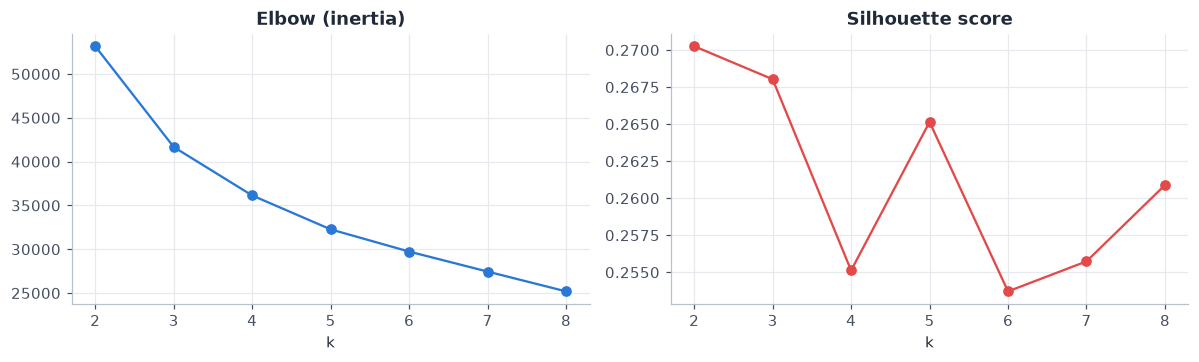

In [2]:
Z = pd.DataFrame({'tenure': df.tenure, 'MonthlyCharges': df.MonthlyCharges, 'NumServices': df.NumServices,
    'contract': df.Contract.map({'Month-to-month': 0, 'One year': 1, 'Two year': 2}), 'fiber': (df.InternetService == 'Fiber optic').astype(int),
    'no_internet': (df.InternetService == 'No').astype(int), 'autopay': df.PaymentMethod.isin(['Bank transfer', 'Credit card']).astype(int),
    'echeck': (df.PaymentMethod == 'Electronic check').astype(int), 'senior': (df.SeniorCitizen == 'Yes').astype(int),
    'household': ((df.Partner == 'Yes') | (df.Dependents == 'Yes')).astype(int)})
S = StandardScaler().fit_transform(Z)
ks = range(2, 9); sil, inertia = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(S); inertia.append(km.inertia_)
    sil.append(silhouette_score(S, km.labels_, sample_size=3000, random_state=1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(list(ks), inertia, 'o-', color=BLUE); ax[0].set_title('Elbow (inertia)'); ax[0].set_xlabel('k')
ax[1].plot(list(ks), sil, 'o-', color=RED); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
plt.tight_layout(); pd.DataFrame({'k': list(ks), 'silhouette': np.round(sil, 3)}).set_index('k').T

Silhouette scores are close between k = 3 and 6 (about 0.25-0.27), so statistics do not pick a clear winner. We use **k = 5** because it gives five groups that are large (at least 940 customers each), clearly different, and easy to describe to a business audience.

In [3]:
km = KMeans(5, n_init=10, random_state=RANDOM_STATE).fit(S); df['cluster'] = km.labels_
prof = df.groupby('cluster').agg(customers=('cluster', 'size'), churn_rate=('ChurnFlag', 'mean'), median_tenure=('tenure', 'median'),
    avg_monthly=('MonthlyCharges', 'mean'), avg_services=('NumServices', 'mean'),
    month_to_month=('Contract', lambda s: (s == 'Month-to-month').mean()), fiber=('InternetService', lambda s: (s == 'Fiber optic').mean()),
    no_internet=('InternetService', lambda s: (s == 'No').mean()), e_check=('PaymentMethod', lambda s: (s == 'Electronic check').mean()),
    senior=('SeniorCitizen', lambda s: (s == 'Yes').mean()))
def name(r):  # transparent, rule-based naming from each cluster's profile
    if r.no_internet > .9: return 'Phone-only budget'
    if r.median_tenure > 50 and r.month_to_month < .2: return 'Loyal multi-service'
    if r.senior > .9: return 'Senior fiber, month-to-month'
    if r.e_check > .9: return 'E-check fiber, month-to-month'
    return 'Mid-tenure month-to-month'
prof['segment'] = prof.apply(name, axis=1); assert prof.segment.is_unique
df['segment'] = df.cluster.map(prof.segment)
prof = prof.set_index('segment')
pf = prof.drop(columns='cluster', errors='ignore').copy()
for c in ['churn_rate', 'month_to_month', 'fiber', 'no_internet', 'e_check', 'senior']: pf[c] = (pf[c] * 100).round(0)
pf[['avg_monthly', 'avg_services']] = pf[['avg_monthly', 'avg_services']].round(1)
pf.sort_values('churn_rate', ascending=False).to_csv(TABLES / 'segment_profiles.csv'); pf.sort_values('churn_rate', ascending=False)

,customers,churn_rate,median_tenure,avg_monthly,avg_services,month_to_month,fiber,no_internet,e_check,senior
segment,,,,,,,,,,
"Senior fiber, month-to-month",944,48.0,25.0,81.4,4.0,84.0,79.0,0.0,62.0,100.0
"E-check fiber, month-to-month",1535,48.0,14.0,76.9,3.9,83.0,68.0,0.0,100.0,0.0
Mid-tenure month-to-month,1501,30.0,16.0,64.4,3.6,81.0,38.0,0.0,0.0,0.0
Loyal multi-service,1537,8.0,65.0,86.2,6.1,5.0,47.0,0.0,8.0,9.0
Phone-only budget,1526,7.0,25.0,21.1,1.0,34.0,0.0,100.0,8.0,3.0


,customers,churners,mrr,mrr_lost,churn_rate,share_of_mrr_lost_%
segment,,,,,,
"E-check fiber, month-to-month",1535,730,118016.4,57267.0,47.6,41.2
"Senior fiber, month-to-month",944,457,76868.2,37100.0,48.4,26.7
Mid-tenure month-to-month,1501,449,96595.8,31020.4,29.9,22.3
Loyal multi-service,1537,120,132469.3,11441.8,7.8,8.2
Phone-only budget,1526,113,32166.8,2301.6,7.4,1.7


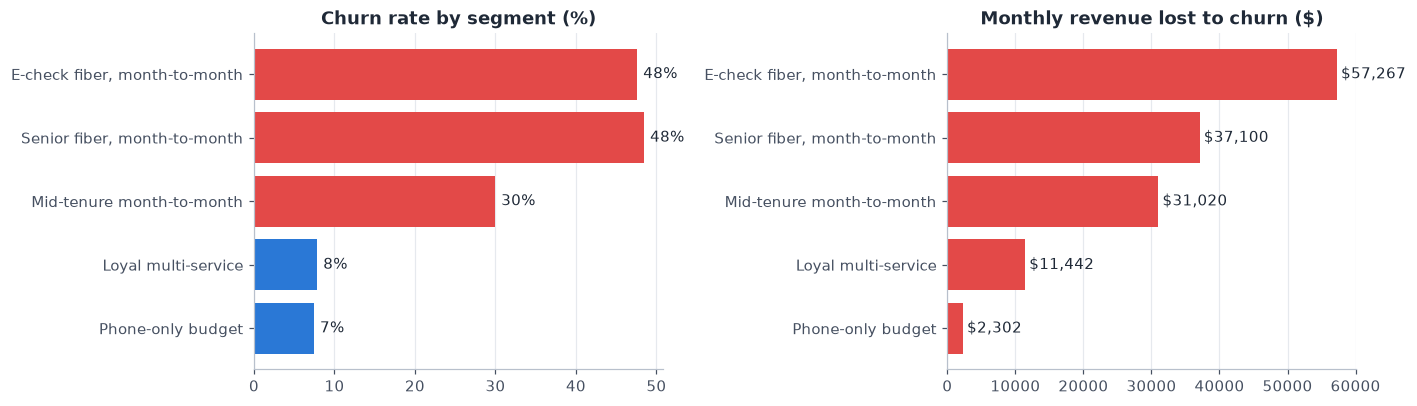

In [4]:
seg = df.groupby('segment').agg(customers=('ChurnFlag', 'size'), churners=('ChurnFlag', 'sum'), mrr=('MonthlyCharges', 'sum'),
    mrr_lost=('MonthlyCharges', lambda s: s[df.loc[s.index, 'ChurnFlag'] == 1].sum())).assign(churn_rate=lambda d: d.churners / d.customers * 100)
seg['share_of_mrr_lost_%'] = seg.mrr_lost / seg.mrr_lost.sum() * 100
seg = seg.sort_values('mrr_lost', ascending=False); seg.round(1).to_csv(TABLES / 'segment_revenue_at_risk.csv')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].barh(seg.index[::-1], seg.churn_rate[::-1], color=[RED if v > 26.5 else BLUE for v in seg.churn_rate[::-1]]); ax[0].set_title('Churn rate by segment (%)')
for i, v in enumerate(seg.churn_rate[::-1]): ax[0].text(v + .8, i, f'{v:.0f}%', va='center')
ax[1].barh(seg.index[::-1], seg.mrr_lost[::-1], color=RED); ax[1].set_title('Monthly revenue lost to churn ($)')
for i, v in enumerate(seg.mrr_lost[::-1]): ax[1].text(v + 600, i, f'${v:,.0f}', va='center')
for a in ax: a.grid(axis='y', visible=False)
plt.tight_layout(); save('12_segments'); seg.round(1)

**Finding.** Two month-to-month fiber groups (electronic-check payers and senior citizens) are 35% of customers but **68% of the monthly revenue lost**; both churn at 48%. The two loyal-looking groups (long-tenure multi-service customers and phone-only customers) churn under 8%.

## 2. Score every customer
Each row is held out from its fold-specific model fit when this retrospective risk table is generated. Hyperparameters were selected using the training split, and this is a single-snapshot sample, so treat these scores as portfolio-analysis outputs—not prospective production probabilities. Held-out test performance is reported separately in Notebook 03.

In [5]:
final = joblib.load(MODELS / 'churn_model.joblib')
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
df['churn_probability'] = cross_val_predict(clone(final), X, y, cv=cv, method='predict_proba')[:, 1]
df['risk_tier'] = pd.cut(df.churn_probability, [-.01, thr, .5, 1.0], labels=['Low', 'Medium', 'High'])
tier = df.groupby('risk_tier', observed=True).agg(customers=('ChurnFlag', 'size'), actual_churn_rate=('ChurnFlag', 'mean'), avg_probability=('churn_probability', 'mean'),
    mrr=('MonthlyCharges', 'sum'), actual_churners=('ChurnFlag', 'sum'))
tier['share_of_all_churners_%'] = tier.actual_churners / tier.actual_churners.sum() * 100
tier = tier.round(3); tier.to_csv(TABLES / 'risk_tiers.csv'); tier

,customers,actual_churn_rate,avg_probability,mrr,actual_churners,share_of_all_churners_%
risk_tier,,,,,,
Low,4171,0.092,0.088,237464.95,385,20.599
Medium,1315,0.351,0.379,93420.40,461,24.666
High,1557,0.657,0.645,125231.25,1023,54.735


**Finding.** The High tier is 22% of customers, churns at **66%** and holds **55% of all churners**. The Low tier (59% of customers) churns at 9%. Predicted probabilities (average 0.65 for High) line up with what actually happened (0.66), so the scores can be read as probabilities.

In [6]:
ACTION = {'Phone-only budget': 'Low priority; light-touch loyalty offer', 'Loyal multi-service': 'Protect: loyalty perks, early renewal, no discounts needed',
          'Senior fiber, month-to-month': 'Proactive call; senior support and a 12-month price lock', 'E-check fiber, month-to-month': 'Offer a bill credit for switching to auto-pay and a 12-month contract',
          'Mid-tenure month-to-month': 'Contract-upgrade offer with a bundled add-on (security / tech support)'}
out = df[['customerID', 'segment', 'Contract', 'tenure', 'MonthlyCharges', 'churn_probability', 'risk_tier', 'ChurnFlag']].copy()
out['recommended_action'] = out.segment.map(ACTION); out['churn_probability'] = out.churn_probability.round(4)
out = out.sort_values('churn_probability', ascending=False)
out.to_csv(TABLES / 'customer_risk_scores.csv', index=False)
print('scored customers:', len(out)); out.head(8)

scored customers: 7043


,customerID,segment,Contract,tenure,MonthlyCharges,churn_probability,risk_tier,ChurnFlag,recommended_action
997,1374-DMZUI,"Senior fiber, month-to-month",Month-to-month,4,94.30,0.8662,High,1,Proactive call; senior support and a 12-month price lock
1976,9497-QCMMS,"Senior fiber, month-to-month",Month-to-month,1,93.55,0.8585,High,1,Proactive call; senior support and a 12-month price lock
4800,9300-AGZNL,"Senior fiber, month-to-month",Month-to-month,1,94.00,0.8583,High,1,Proactive call; senior support and a 12-month price lock
3749,4424-TKOPW,"Senior fiber, month-to-month",Month-to-month,2,93.85,0.8558,High,1,Proactive call; senior support and a 12-month price lock
6368,2720-WGKHP,"Senior fiber, month-to-month",Month-to-month,2,94.00,0.8543,High,1,Proactive call; senior support and a 12-month price lock
301,8098-LLAZX,"Senior fiber, month-to-month",Month-to-month,4,95.45,0.8499,High,1,Proactive call; senior support and a 12-month price lock
3380,5178-LMXOP,"Senior fiber, month-to-month",Month-to-month,1,95.10,0.8463,High,1,Proactive call; senior support and a 12-month price lock
2208,7216-EWTRS,"Senior fiber, month-to-month",Month-to-month,1,100.80,0.8440,High,1,Proactive call; senior support and a 12-month price lock


## 3. What is a retention campaign worth? Sensitivity of the business case
The headline number depends on two assumptions we cannot know from this data: what an offer costs, and how often it works. Rather than pretend, we show the range.

offer success rate,10%,20%,30%,40%,50%
offer cost,,,,,
$20,11430.0,31015.0,50601.0,70186.0,89772.0
$35,5313.0,24899.0,44484.0,64069.0,83655.0
$50,-804.0,18782.0,38367.0,57953.0,77538.0
$75,-10998.0,8587.0,28173.0,47758.0,67344.0
$100,-21193.0,-1607.0,17978.0,37564.0,57149.0


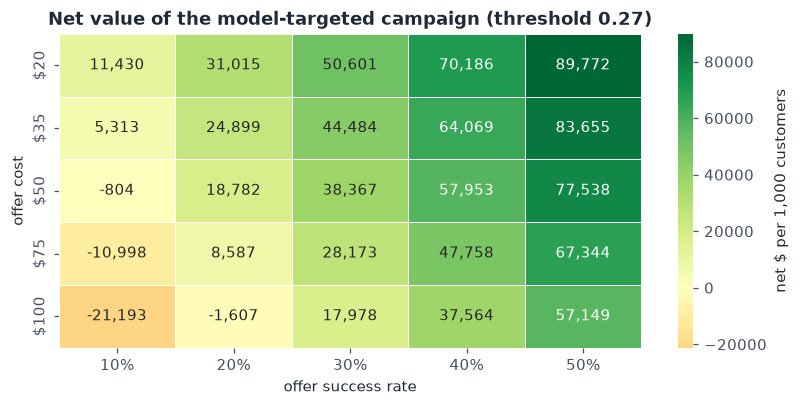

In [7]:
mon = df.MonthlyCharges.values; p = df.churn_probability.values; yy = df.ChurnFlag.values
costs = [20, 35, 50, 75, 100]; rates = [.10, .20, .30, .40, .50]
grid = pd.DataFrame({f'{int(r*100)}%': [campaign_value(yy, p, mon, thr, c, r, ASSUMPTIONS['horizon_months'])['net'] / len(df) * 1000 for c in costs] for r in rates}, index=[f'${c}' for c in costs])
grid.index.name = 'offer cost'; grid.columns.name = 'offer success rate'
plt.figure(figsize=(7.5, 3.8)); sns.heatmap(grid, annot=True, fmt=',.0f', cmap='RdYlGn', center=0, cbar_kws={'label': 'net $ per 1,000 customers'}, linewidths=.5)
plt.title(f'Net value of the model-targeted campaign (threshold {thr:.2f})'); plt.tight_layout(); save('13_roi_sensitivity')
grid.round(0).to_csv(TABLES / 'roi_sensitivity.csv'); grid.round(0)

In [8]:
# Break-even success rate at the base-case offer cost
c = ASSUMPTIONS['offer_cost']; sel = p >= thr
gain_per_unit_rate = (mon[sel & (yy == 1)] * ASSUMPTIONS['horizon_months']).sum()
cost_total = c * sel.sum()
print(f'Contacted: {sel.sum():,} customers ({sel.mean():.0%} of base), reaching {(sel & (yy == 1)).sum() / yy.sum():.0%} of churners')
print(f'Break-even offer success rate at ${c:.0f} per offer: {cost_total / gain_per_unit_rate:.1%} (we assumed {ASSUMPTIONS["offer_success_rate"]:.0%})')

Contacted: 2,872 customers (41% of base), reaching 79% of churners
Break-even offer success rate at $50 per offer: 10.4% (we assumed 30%)


**Finding.** At $50 per offer the campaign breaks even if offers rescue **about 10%** of would-be churners; we assumed 30%. It only loses money in the bottom-left of the table (expensive offers that rarely work). The assumptions are illustrative: the real success rate should be measured with a small A/B test before scaling.

## 4. Executive dashboard (one page)

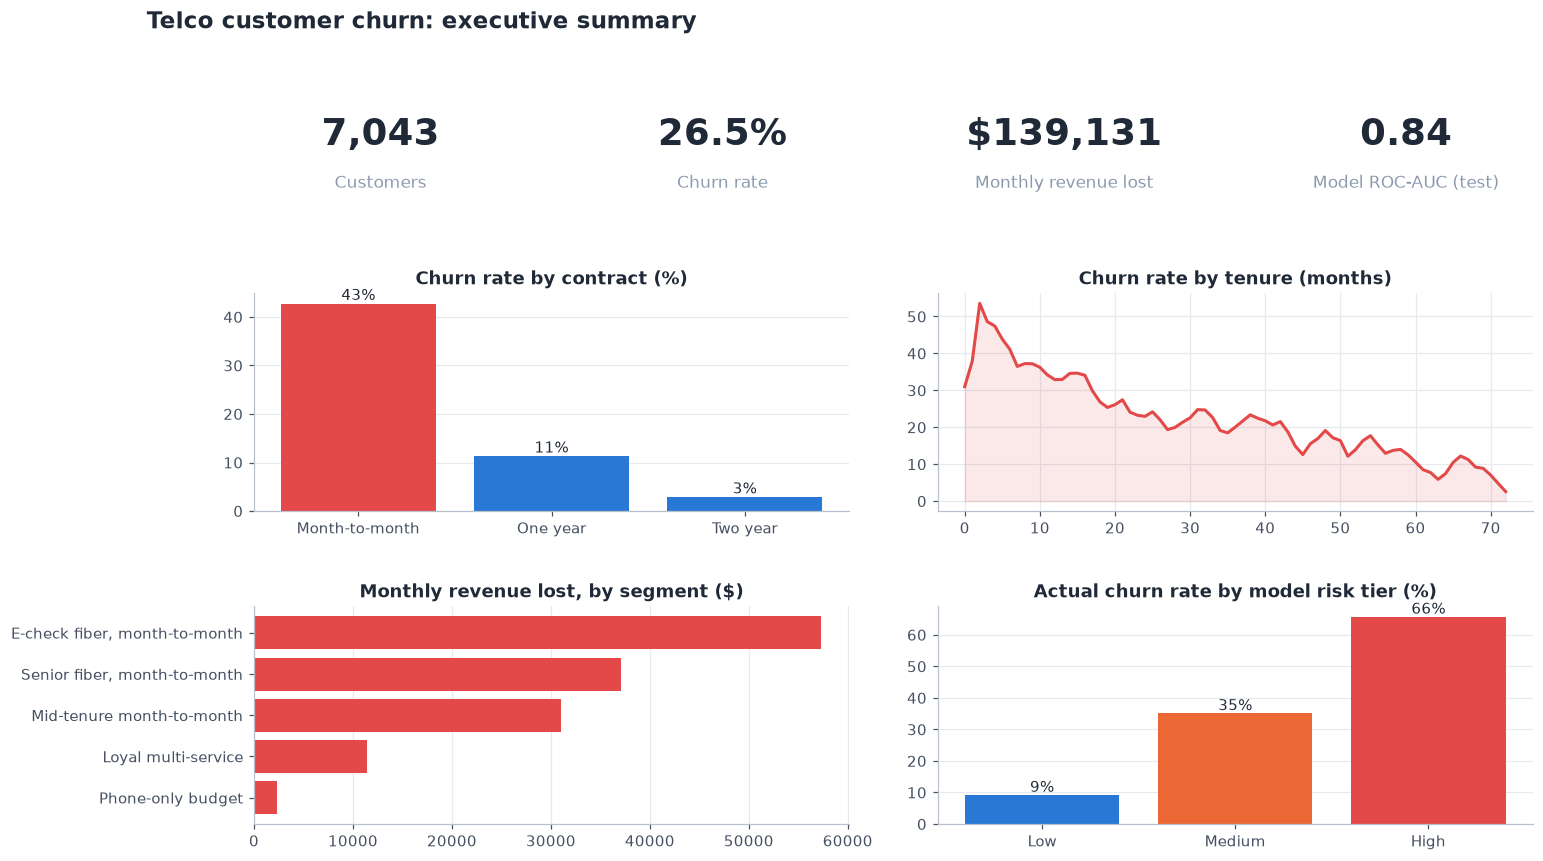

In [9]:
fig = plt.figure(figsize=(15, 8.4)); gs = fig.add_gridspec(3, 4, height_ratios=[.55, 1.4, 1.4], hspace=.55, wspace=.35)
churned = df[df.ChurnFlag == 1]
kp = [('Customers', f'{len(df):,}'), ('Churn rate', f'{df.ChurnFlag.mean():.1%}'), ('Monthly revenue lost', f'${churned.MonthlyCharges.sum():,.0f}'), ('Model ROC-AUC (test)', f"{M['test']['roc_auc']:.2f}")]
for i, (k, v) in enumerate(kp):
    a = fig.add_subplot(gs[0, i]); a.axis('off'); a.text(.5, .62, v, ha='center', fontsize=24, fontweight='bold', color=style.INK); a.text(.5, .12, k, ha='center', fontsize=11, color=GREY)
a = fig.add_subplot(gs[1, 0:2]); t = df.groupby('Contract').ChurnFlag.mean().reindex(['Month-to-month', 'One year', 'Two year']) * 100
a.bar(t.index, t.values, color=[RED, BLUE, BLUE]); a.set_title('Churn rate by contract (%)'); a.grid(axis='x', visible=False)
for i, v in enumerate(t.values): a.text(i, v + .8, f'{v:.0f}%', ha='center')
a = fig.add_subplot(gs[1, 2:4]); s = df.groupby('tenure').ChurnFlag.mean().rolling(3, center=True, min_periods=1).mean() * 100; a.plot(s.index, s.values, color=RED, lw=2); a.fill_between(s.index, s.values, color=RED, alpha=.12)
a.set_title('Churn rate by tenure (months)')
a = fig.add_subplot(gs[2, 0:2]); a.barh(seg.index[::-1], seg.mrr_lost[::-1], color=RED); a.set_title('Monthly revenue lost, by segment ($)'); a.grid(axis='y', visible=False)
a = fig.add_subplot(gs[2, 2:4]); a.bar(tier.index.astype(str), tier.actual_churn_rate * 100, color=[BLUE, ORANGE, RED]); a.set_title('Actual churn rate by model risk tier (%)'); a.grid(axis='x', visible=False)
for i, v in enumerate(tier.actual_churn_rate * 100): a.text(i, v + 1, f'{v:.0f}%', ha='center')
fig.suptitle('Telco customer churn: executive summary', fontsize=15, fontweight='bold', x=.06, ha='left', y=.99)
save('00_executive_dashboard')